In [79]:
# ---------------------------------------------------------------
# 0. Imports & global settings
# ---------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
RANDOM_STATE = 42


---
## 1. Data Understanding

In [80]:
# Load the dataset with memory-friendly dtypes.
# The dataset is small, but these dtypes keep the notebook safe on laptops
# and scale better if the CSV grows later.
dtype_map = {
    'user_id': 'int32',
    'age': 'int16',
    'monthly_income': 'float32',
    'credit_score': 'int16',
    'purchase_amount': 'float32',
    'bnpl_installments': 'int8',
    'repayment_delay_days': 'int16',
    'missed_payments': 'int8',
    'default_flag': 'int8',
    'app_usage_frequency': 'float32',
    'debt_to_income_ratio': 'float32',
    'risk_score': 'float32',
}

category_cols = ['employment_type', 'product_category', 'location', 'customer_segment']

df = pd.read_csv(
    'Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv',
    dtype=dtype_map,
    parse_dates=['transaction_date']
)

for col in category_cols:
    df[col] = df[col].astype('category')

memory_mb = df.memory_usage(deep=True).sum() / 1024**2
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Memory usage: {memory_mb:.2f} MB')
df.head()


Shape: 10,345 rows × 17 columns
Memory usage: 0.44 MB


,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
0,1,56,Salaried,68529.500000,552,5000.000000,Electronics,12,13,1,0,8.49,Australia,2023-06-10,0.072961,165.199997,Medium Risk
1,2,19,Student,7247.850098,300,1073.229980,Fashion,12,13,1,0,3.09,USA,2024-10-07,0.148076,266.000000,High Risk
2,3,20,Self-Employed,41582.261719,471,5000.000000,Electronics,3,19,2,0,3.33,Australia,2023-04-05,0.120244,229.600006,High Risk
3,4,21,Salaried,14423.459961,300,4076.830078,Sports,6,18,5,1,5.86,Germany,2023-06-24,0.282653,356.000000,High Risk
4,5,43,Salaried,42845.500000,512,5000.000000,Electronics,9,0,0,0,7.36,India,2024-10-19,0.116698,135.199997,High Risk


In [81]:
# Column descriptions (from dataset documentation + inspection)
descriptions = {
    'user_id':              'Unique customer ID (identifier — dropped before modeling)',
    'age':                  'Customer age in years',
    'employment_type':      'Salaried / Self-Employed / Student / Unemployed',
    'monthly_income':       'Customer monthly income (local currency)',
    'credit_score':         'Credit bureau score (higher = better credit)',
    'purchase_amount':      'Amount of the BNPL purchase',
    'product_category':     'Category of the purchased product',
    'bnpl_installments':    'Number of installments chosen',
    'repayment_delay_days': 'Days of delay on repayments (behavioral)',
    'missed_payments':      'Count of missed payments (behavioral)',
    'default_flag':         'TARGET — 1 if customer defaulted, 0 otherwise',
    'app_usage_frequency':  'App engagement score',
    'location':             'Country of the customer',
    'transaction_date':     'Date of the BNPL transaction',
    'debt_to_income_ratio': 'Debt / Income ratio',
    'risk_score':           'Pre-computed internal risk score (potential leakage — see note)',
    'customer_segment':     'Pre-computed risk segment Low/Medium/High (potential leakage — see note)'
}
pd.DataFrame(descriptions.items(), columns=['column', 'description'])

,column,description
0,user_id,Unique customer ID (identifier — dropped befor...
1,age,Customer age in years
2,employment_type,Salaried / Self-Employed / Student / Unemployed
3,monthly_income,Customer monthly income (local currency)
4,credit_score,Credit bureau score (higher = better credit)
5,purchase_amount,Amount of the BNPL purchase
6,product_category,Category of the purchased product
7,bnpl_installments,Number of installments chosen
8,repayment_delay_days,Days of delay on repayments (behavioral)
9,missed_payments,Count of missed payments (behavioral)


In [82]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               10345 non-null  int32         
 1   age                   10345 non-null  int16         
 2   employment_type       10345 non-null  category      
 3   monthly_income        10345 non-null  float32       
 4   credit_score          10345 non-null  int16         
 5   purchase_amount       10345 non-null  float32       
 6   product_category      10345 non-null  category      
 7   bnpl_installments     10345 non-null  int8          
 8   repayment_delay_days  10345 non-null  int16         
 9   missed_payments       10345 non-null  int8          
 10  default_flag          10345 non-null  int8          
 11  app_usage_frequency   10345 non-null  float32       
 12  location              10345 non-null  category      
 13  transaction_date      10345

In [83]:
# Summary statistics for numerical features
df.describe().T

,count,mean,min,25%,50%,75%,max,std
user_id,10345.0,5173.0,1.0,2587.0,5173.0,7759.0,10345.0,2986.488601
age,10345.0,38.559884,18.0,28.0,39.0,49.0,59.0,12.131789
monthly_income,10345.0,35053.382812,5000.0,12207.019531,23800.519531,55276.929688,145767.125,27084.517578
credit_score,10345.0,448.176124,300.0,332.0,403.0,547.0,850.0,136.518332
purchase_amount,10345.0,3979.402588,100.0,2990.719971,5000.0,5000.0,5000.0,1500.828491
bnpl_installments,10345.0,7.477525,3.0,3.0,9.0,9.0,12.0,3.362867
repayment_delay_days,10345.0,8.742774,0.0,2.0,9.0,14.0,33.0,6.781849
missed_payments,10345.0,1.01595,0.0,0.0,1.0,2.0,7.0,0.996726
default_flag,10345.0,0.390527,0.0,0.0,0.0,1.0,1.0,0.487892
app_usage_frequency,10345.0,5.524102,1.0,3.3,5.55,7.75,10.0,2.590364


In [84]:
# Summary for categorical features
# `include=['category']` works because we loaded low-cardinality text columns as category dtype.
df.describe(include=['category']).T


,count,unique,top,freq
employment_type,10345,4,Salaried,2632
product_category,10345,5,Fashion,2166
location,10345,6,Germany,1760
customer_segment,10345,3,High Risk,7569


In [85]:
# Identify variable types
numerical_cols = [
    'age', 'monthly_income', 'credit_score', 'purchase_amount',
    'bnpl_installments', 'repayment_delay_days', 'missed_payments',
    'app_usage_frequency', 'debt_to_income_ratio', 'risk_score'
]
categorical_cols = ['employment_type', 'product_category', 'location', 'customer_segment']
print('Numerical  :', numerical_cols)
print('Categorical:', categorical_cols)
print('Target     : default_flag')

Numerical  : ['age', 'monthly_income', 'credit_score', 'purchase_amount', 'bnpl_installments', 'repayment_delay_days', 'missed_payments', 'app_usage_frequency', 'debt_to_income_ratio', 'risk_score']
Categorical: ['employment_type', 'product_category', 'location', 'customer_segment']
Target     : default_flag


              count    pct
default_flag              
0              6305  60.95
1              4040  39.05


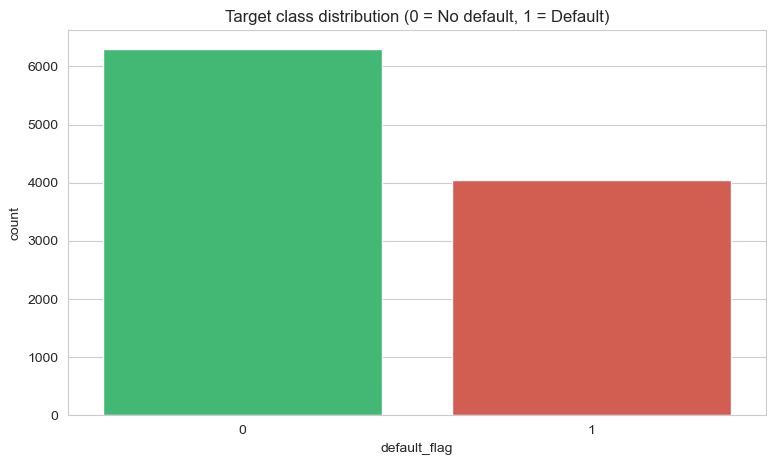

In [87]:
# Target class balance
target_counts = df['default_flag'].value_counts().sort_index()
target_pct = df['default_flag'].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({'count': target_counts, 'pct': target_pct.round(2)}))

sns.countplot(x='default_flag', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Target class distribution (0 = No default, 1 = Default)')
plt.show()

**Observation.** The data is moderately imbalanced (≈61% non-default, ≈39% default). It is imbalanced enough to hurt a naïve classifier's recall on the default class, but not so skewed that we need SMOTE — using `class_weight='balanced'` inside each model is sufficient.

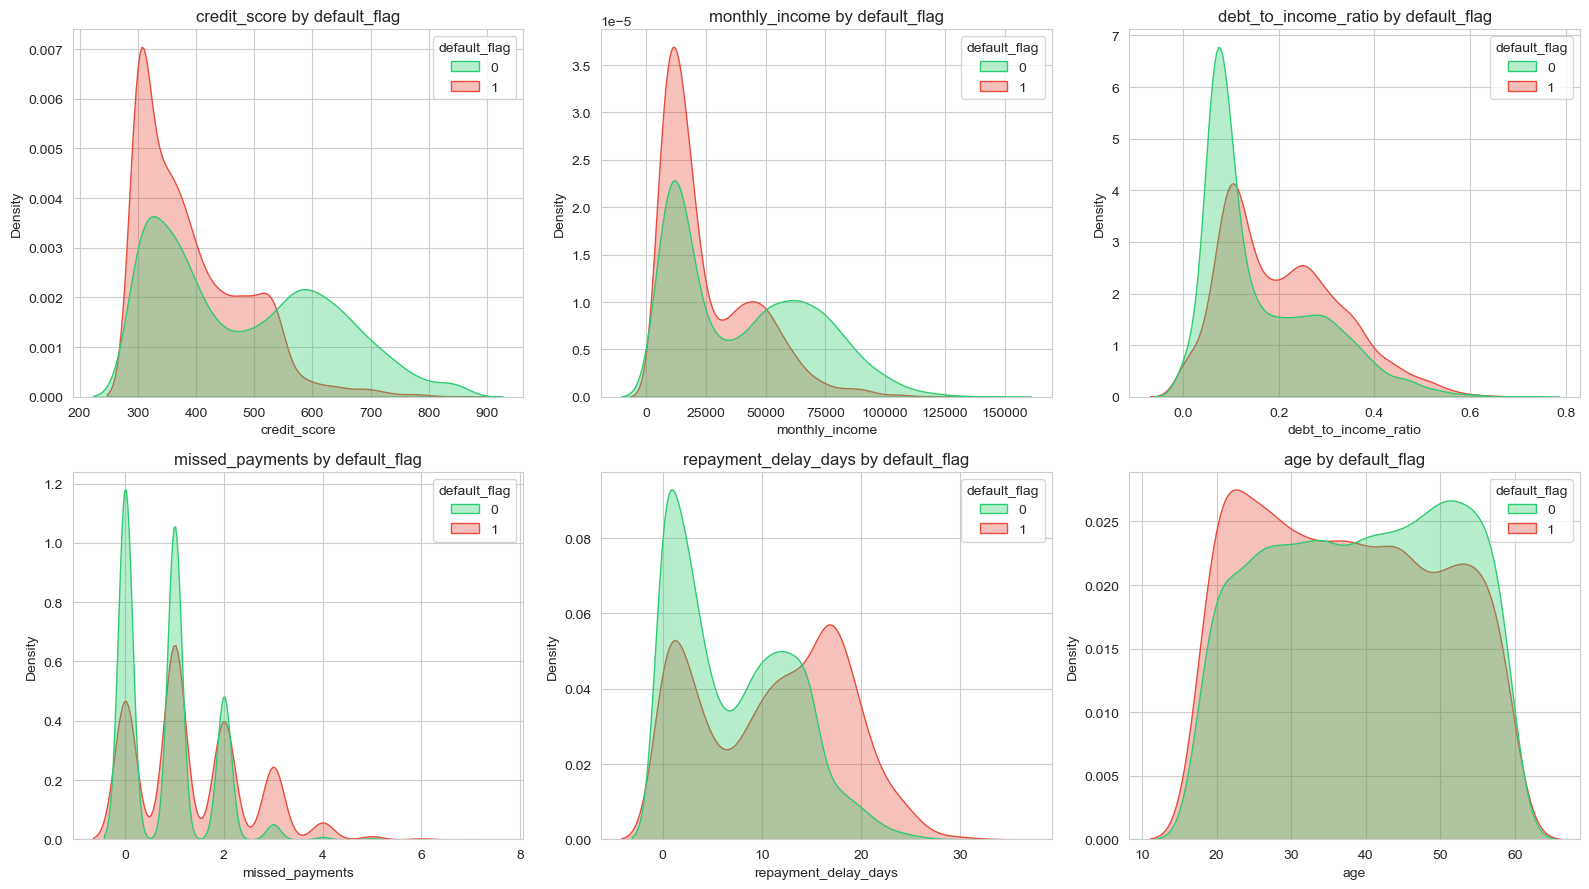

In [88]:
# Quick exploratory plots — numeric features vs. default
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(),
                    ['credit_score', 'monthly_income', 'debt_to_income_ratio',
                     'missed_payments', 'repayment_delay_days', 'age']):
    sns.kdeplot(data=df, x=col, hue='default_flag', common_norm=False,
                palette=['#2ecc71', '#e74c3c'], ax=ax, fill=True, alpha=0.35)
    ax.set_title(f'{col} by default_flag')
plt.tight_layout(); plt.show()

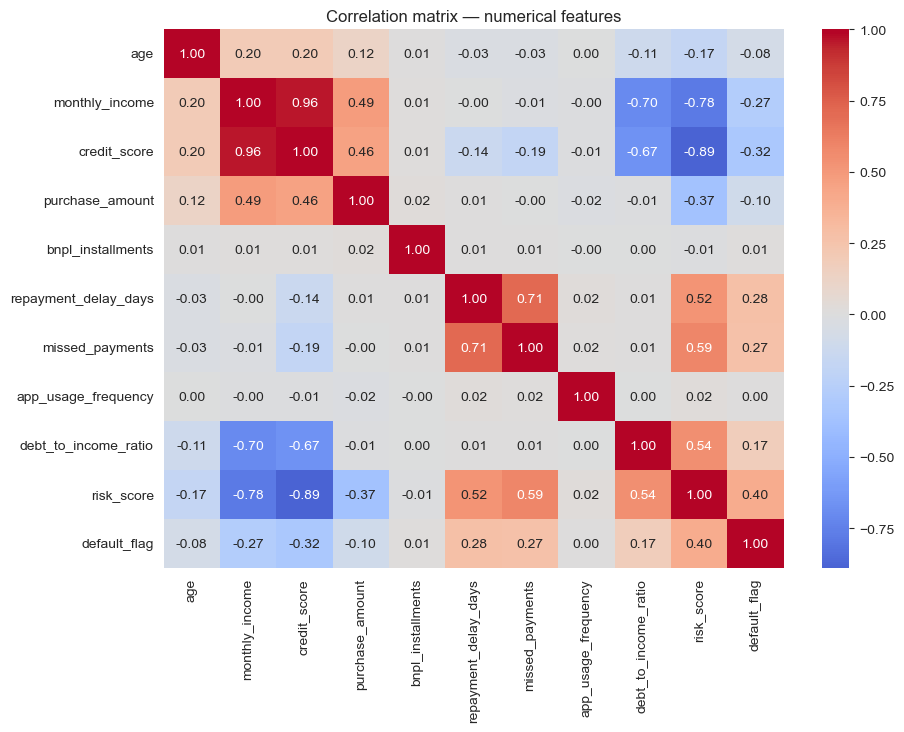

In [89]:
# Correlation heatmap for numeric features
plt.figure(figsize=(10, 7))
sns.heatmap(df[numerical_cols + ['default_flag']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix — numerical features')
plt.show()

In [90]:
# 2.1  Drop non-informative / non-model columns
# user_id is only an identifier. transaction_date is excluded to keep this baseline simple
# and avoid accidental time leakage without careful feature engineering.
model_df = df.drop(columns=['user_id', 'transaction_date'])

# 2.2  Sanity check — report any missing values.
# The imputers below still handle missing values if the dataset changes later.
missing = model_df.isnull().sum()
print('Columns with missing values:')
print(missing[missing > 0] if (missing > 0).any() else '  (none — dataset is complete)')

# 2.3  Split features / target
X = model_df.drop(columns=['default_flag'])
y = model_df['default_flag']

# 2.4  Stratified train / test split keeps the default rate stable in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# GradientBoostingClassifier does not support class_weight directly, so we pass
# balanced sample weights during fitting to make defaults more costly to miss.
gb_sample_weight = compute_sample_weight(class_weight='balanced', y=y_train)

print(f'Train: {X_train.shape}, default rate = {y_train.mean():.3f}')
print(f'Test : {X_test.shape}, default rate = {y_test.mean():.3f}')


Columns with missing values:
  (none — dataset is complete)
Train: (8276, 14), default rate = 0.391
Test : (2069, 14), default rate = 0.391


In [91]:
# 2.5  Build preprocessing pipeline
# Numeric features are median-imputed and scaled for Logistic Regression.
# Tree models do not require scaling, but using one shared preprocessor keeps the
# comparison consistent and avoids duplicate transformation code.
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe,     numerical_cols),
    ('cat', categorical_pipe, categorical_cols)
], remainder='drop')
preprocessor


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'monthly_income', 'credit_score',
                                  'purchase_amount', 'bnpl_installments',
                                  'repayment_delay_days', 'missed_payments',
                                  'app_usage_frequency', 'debt_to_income_ratio',
                                  'risk_score']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(dtype=<class 'numpy.float32'>,
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['employment_type', 'product_category',
                                  'location', 'customer_segment'])])

In [92]:
models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            solver='lbfgs',
            random_state=42
        ))
    ]),
    
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            min_samples_leaf=10,
            class_weight='balanced',
            n_jobs=-1,
            random_state=42
        ))
    ]),
    
    'Gradient Boosting': Pipeline([
        ('prep', preprocessor),
        ('clf', GradientBoostingClassifier(
            n_estimators=80,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.8,
            random_state=42
        ))
    ]),
}


In [93]:
# 3.2  Fit each model + lightweight stratified CV on training data.
# Use 3 folds and n_jobs=1 to avoid multiple full pipeline copies in memory.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
fit_params = {
    'Gradient Boosting': {'clf__sample_weight': gb_sample_weight}
}

for name, pipe in models.items():
    cv_scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring='recall',
        n_jobs=1,
        fit_params=fit_params.get(name)
    )
    pipe.fit(X_train, y_train, **fit_params.get(name, {}))
    print(
        f'{name:<22} | 3-fold CV recall = {cv_scores.mean():.4f} '
        f'(+/- {cv_scores.std():.4f}) | fitted on full train set'
    )


Logistic Regression    | 3-fold CV recall = 0.6900 (+/- 0.0029) | fitted on full train set
Random Forest          | 3-fold CV recall = 0.8001 (+/- 0.0319) | fitted on full train set
Gradient Boosting      | 3-fold CV recall = 0.7404 (+/- 0.0470) | fitted on full train set


In [94]:
# 4.1  Evaluate each model on the held-out test set.
# Recall for class 1 is the key credit-risk metric: a false negative means a
# customer who may default is incorrectly treated as low risk.
results = []
trained_preds = {}

for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    trained_preds[name] = (y_pred, y_proba)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (class 1)': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        'Recall (class 1)': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        'F1 (class 1)': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df


,Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),ROC-AUC
Model,,,,,
Logistic Regression,0.6675,0.5595,0.6980,0.6211,0.7587
Random Forest,0.6240,0.5114,0.8354,0.6344,0.7762
Gradient Boosting,0.6332,0.5196,0.8057,0.6317,0.7778



===== Logistic Regression =====
                precision    recall  f1-score   support

No Default (0)     0.7700    0.6479    0.7037      1261
   Default (1)     0.5595    0.6980    0.6211       808

      accuracy                         0.6675      2069
     macro avg     0.6648    0.6730    0.6624      2069
  weighted avg     0.6878    0.6675    0.6715      2069


===== Random Forest =====
                precision    recall  f1-score   support

No Default (0)     0.8224    0.4885    0.6129      1261
   Default (1)     0.5114    0.8354    0.6344       808

      accuracy                         0.6240      2069
     macro avg     0.6669    0.6619    0.6237      2069
  weighted avg     0.7010    0.6240    0.6213      2069


===== Gradient Boosting =====
                precision    recall  f1-score   support

No Default (0)     0.8076    0.5226    0.6346      1261
   Default (1)     0.5196    0.8057    0.6317       808

      accuracy                         0.6332      2069
     

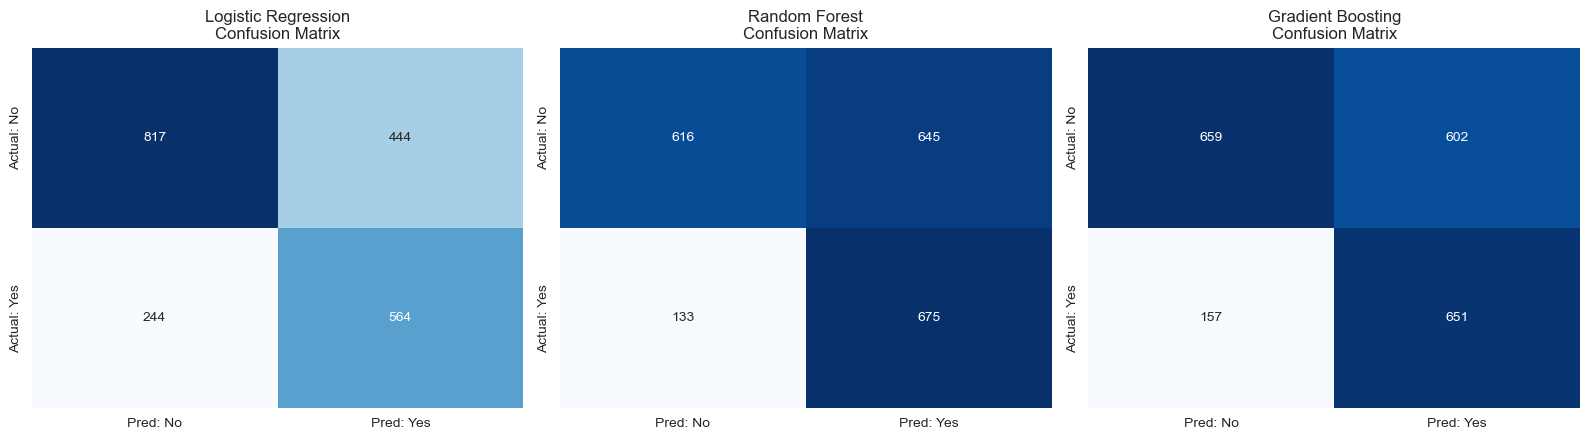

In [95]:
# 4.2  Per-model classification report + confusion matrix
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, (y_pred, _)) in zip(axes, trained_preds.items()):
    print(f'\n===== {name} =====')
    print(classification_report(y_test, y_pred, digits=4,
                                 target_names=['No Default (0)', 'Default (1)']))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred: No', 'Pred: Yes'],
                yticklabels=['Actual: No', 'Actual: Yes'])
    ax.set_title(f'{name}\nConfusion Matrix')
plt.tight_layout(); plt.show()

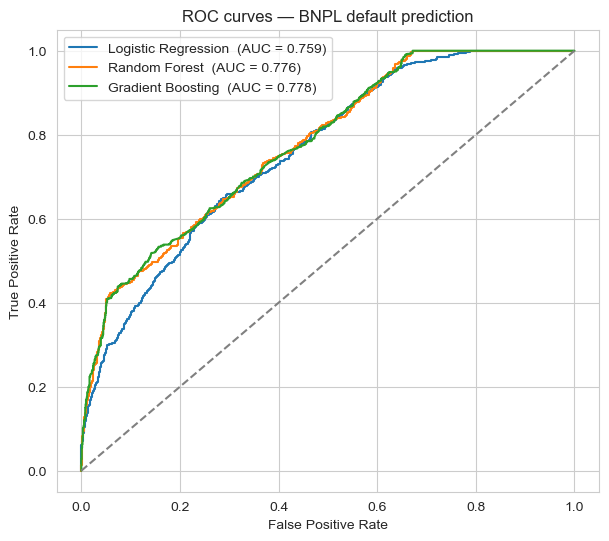

In [74]:
# 4.3  ROC curves (visual validation)
plt.figure(figsize=(7, 6))
for name, (_, y_proba) in trained_preds.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name}  (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', color='grey')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC curves — BNPL default prediction')
plt.legend(); plt.show()

---
## 5. Model Comparison

In [75]:
# 5.1 Comparison table sorted by Recall (class 1) — our primary business metric.
# In BNPL credit risk, missing a future defaulter is usually more expensive than
# adding a manual review step for a good customer.
comparison = results_df.sort_values('Recall (class 1)', ascending=False)
comparison


,Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),ROC-AUC
Model,,,,,
Random Forest,0.6240,0.5114,0.8354,0.6344,0.7762
Gradient Boosting,0.6332,0.5196,0.8057,0.6317,0.7778
Logistic Regression,0.6675,0.5595,0.6980,0.6211,0.7587


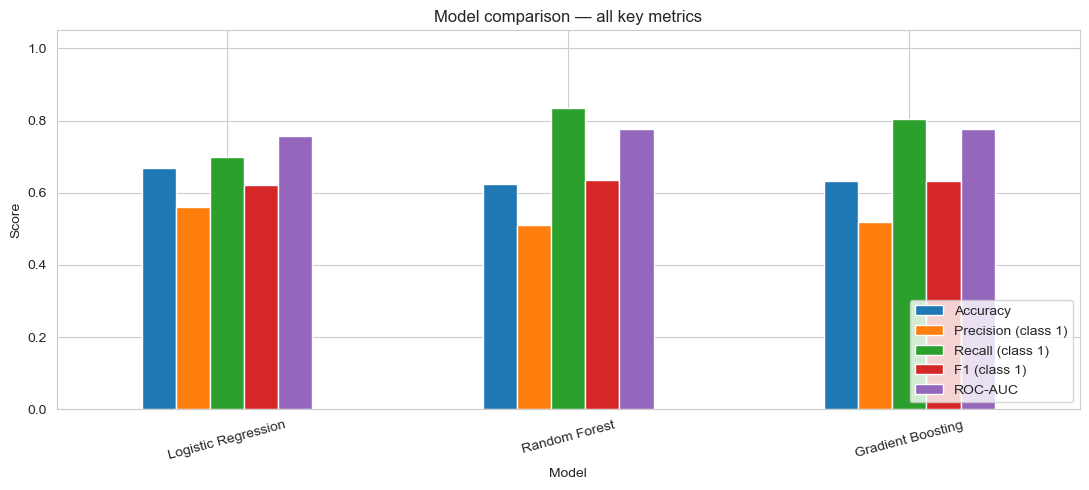

Best model for this project (highest default recall): Random Forest
Best by F1     (minority class) : Random Forest
Best by ROC-AUC                 : Gradient Boosting

Recall-first decision rule: choose the model with the highest class-1 recall,
then use precision/F1 as tie-breakers to control unnecessary manual reviews.


In [76]:
# 5.2 Visual comparison
ax = results_df[['Accuracy', 'Precision (class 1)', 'Recall (class 1)',
                  'F1 (class 1)', 'ROC-AUC']].plot(kind='bar', figsize=(11, 5))
ax.set_title('Model comparison — all key metrics')
ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

best_by_recall = results_df['Recall (class 1)'].idxmax()
best_by_f1 = results_df['F1 (class 1)'].idxmax()
best_by_auc = results_df['ROC-AUC'].idxmax()

print(f'Best model for this project (highest default recall): {best_by_recall}')
print(f'Best by F1     (minority class) : {best_by_f1}')
print(f'Best by ROC-AUC                 : {best_by_auc}')

print()
print('Recall-first decision rule: choose the model with the highest class-1 recall,')
print('then use precision/F1 as tie-breakers to control unnecessary manual reviews.')


---
## 6. Feature Importance

In [77]:
# 6.1 Pull feature importance from the Random Forest (required by the brief)
rf_pipe = models['Random Forest']

# Re-build the exact feature names after one-hot encoding
ohe = rf_pipe.named_steps['prep'].named_transformers_['cat'].named_steps['onehot']
cat_feature_names = list(ohe.get_feature_names_out(categorical_cols))
feature_names = numerical_cols + cat_feature_names

importances = rf_pipe.named_steps['clf'].feature_importances_
fi = (pd.DataFrame({'feature': feature_names, 'importance': importances})
        .sort_values('importance', ascending=False)
        .reset_index(drop=True))
fi.head(15)

,feature,importance
0,repayment_delay_days,0.195496
1,risk_score,0.177511
2,credit_score,0.154110
3,customer_segment_High Risk,0.132251
4,missed_payments,0.084400
5,customer_segment_Medium Risk,0.064831
6,monthly_income,0.055648
7,debt_to_income_ratio,0.050356
8,app_usage_frequency,0.015856
9,age,0.013186


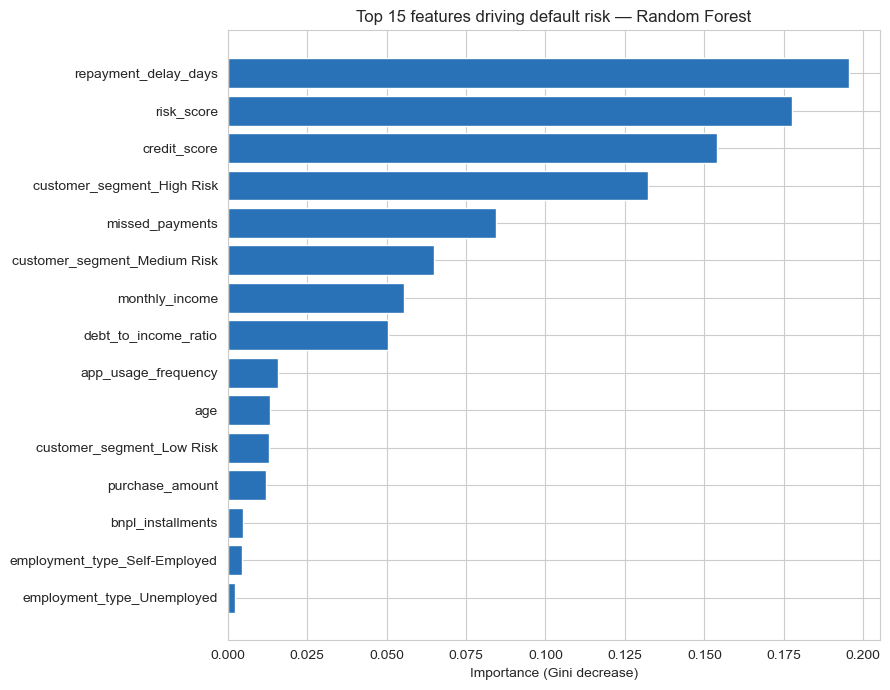

In [78]:
# 6.2 Plot top-15 features
top = fi.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top['feature'], top['importance'], color='#2a72b8')
plt.title('Top 15 features driving default risk — Random Forest')
plt.xlabel('Importance (Gini decrease)')
plt.tight_layout(); plt.show()